# Trabajo 4: Visualización de datos con Matplotlib y Seaborn

Análisis visual de las ventas minoristas del dataset **Superstore 2012**: ventas, beneficios, descuentos, categorías, mercados y envíos.

Contenido:
1. Carga y preparación de datos (Pandas)
2. Gráficos univariantes (Matplotlib y Seaborn)
3. Gráficos bivariantes (Matplotlib y Seaborn)
4. Gráficos multivariantes (Matplotlib y Seaborn)
5. Figura con subplots
6. Conclusiones

## 1. Configuración del entorno

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Estilo general para todos los gráficos
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titleweight"] = "bold"

## 2. Carga y exploración de los datos

In [2]:
df = pd.read_csv("superstore_dataset2012.csv")

print("Filas y columnas:", df.shape)
df.head()

Filas y columnas: (4246, 24)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
0,21896,ID-2012-71858,1/2/2012,7/2/2012,Standard Class,CP-12085,Cathy Prescott,Corporate,Jakarta,Jakarta,...,TEC-PH-10003784,Technology,Phones,"Motorola Signal Booster, with Caller ID",593.9895,5,0.17,-71.7105,52.22,Medium
1,4323,MX-2012-154459,1/2/2012,6/2/2012,Standard Class,JF-15190,Jamie Frazer,Consumer,Santiago,Santiago,...,TEC-PH-10002102,Technology,Phones,"Nokia Headset, Cordless",151.9200,3,0.00,71.4000,32.94,High
2,2829,MX-2012-114461,1/2/2012,5/2/2012,Standard Class,RM-19375,Raymond Messe,Consumer,Escuintla,Escuintla,...,TEC-AC-10002760,Technology,Accessories,"Memorex Memory Card, Erganomic",200.1600,3,0.00,0.0000,28.95,High
3,2828,MX-2012-114461,1/2/2012,5/2/2012,Standard Class,RM-19375,Raymond Messe,Consumer,Escuintla,Escuintla,...,FUR-CH-10001423,Furniture,Chairs,"Harbour Creations Rocking Chair, Black",192.8800,2,0.00,54.0000,19.27,High
4,6762,MX-2012-151904,1/2/2012,3/2/2012,First Class,DJ-13420,Denny Joy,Corporate,Villa Canales,Guatemala,...,OFF-PA-10003571,Office Supplies,Paper,"Enermax Cards & Envelopes, Recycled",94.0200,3,0.00,1.8600,10.73,Medium


In [3]:
# Tipos de datos de cada columna
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4246 entries, 0 to 4245
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          4246 non-null   int64  
 1   Order ID        4246 non-null   str    
 2   Order Date      4246 non-null   str    
 3   Ship Date       4246 non-null   str    
 4   Ship Mode       4246 non-null   str    
 5   Customer ID     4246 non-null   str    
 6   Customer Name   4246 non-null   str    
 7   Segment         4246 non-null   str    
 8   City            4246 non-null   str    
 9   State           4246 non-null   str    
 10  Country         4246 non-null   str    
 11  Postal Code     823 non-null    float64
 12  Market          4246 non-null   str    
 13  Region          4246 non-null   str    
 14  Product ID      4246 non-null   str    
 15  Category        4246 non-null   str    
 16  Sub-Category    4246 non-null   str    
 17  Product Name    4246 non-null   str    
 18 

In [4]:
# Valores nulos por columna
nulos = df.isnull().sum()
print(nulos[nulos > 0])
print("\nFilas duplicadas:", df.duplicated().sum())

Postal Code    3423
dtype: int64

Filas duplicadas: 0


In [5]:
# Resumen estadístico de las variables numéricas
df[["Sales", "Quantity", "Discount", "Profit", "Shipping Cost"]].describe().round(2)

,Sales,Quantity,Discount,Profit,Shipping Cost
count,4246.00,4246.00,4246.00,4246.00,4246.00
mean,237.03,3.44,0.15,27.70,24.54
std,426.97,2.23,0.22,147.46,50.42
min,1.11,1.00,0.00,-1806.24,0.03
25%,30.56,2.00,0.00,-0.06,2.61
50%,82.53,3.00,0.00,9.03,7.60
75%,245.81,5.00,0.20,35.90,23.53
max,5759.96,14.00,0.80,2229.02,759.47


### Preparación de los datos

- **Nulos:** solo `Postal Code` tiene valores nulos (la mayoría de países no lo registran). Como no se usa en el análisis, se elimina la columna en lugar de borrar filas.
- **Fechas:** `Order Date` y `Ship Date` vienen como texto y en dos formatos mezclados (`7/2/2012` y `13-01-2012`). Los dos son día/mes/año, así que se unifica el separador y se convierten a `datetime`.
- **Columnas nuevas:** mes del pedido, días de envío y si la venta tuvo pérdida.

In [6]:
# Eliminar la columna con nulos que no se usa
df = df.drop(columns=["Postal Code"])

# Unificar el separador de fecha y convertir a datetime (formato día/mes/año)
df["Order Date"] = pd.to_datetime(df["Order Date"].str.replace("-", "/"), format="%d/%m/%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"].str.replace("-", "/"), format="%d/%m/%Y")

# Columnas derivadas para el análisis
df["Mes"] = df["Order Date"].dt.month
df["Dias_Envio"] = (df["Ship Date"] - df["Order Date"]).dt.days
df["Con_Perdida"] = df["Profit"] < 0

print(df[["Order Date", "Ship Date", "Mes", "Dias_Envio"]].dtypes)
print("\nRango de fechas:", df["Order Date"].min().date(), "a", df["Order Date"].max().date())
print("Días de envío: mínimo", df["Dias_Envio"].min(), "| máximo", df["Dias_Envio"].max())
print(f"Ventas con pérdida: {df['Con_Perdida'].mean() * 100:.1f}%")

Order Date    datetime64[us]
Ship Date     datetime64[us]
Mes                    int32
Dias_Envio             int64
dtype: object

Rango de fechas: 2012-01-02 a 2012-12-12
Días de envío: mínimo 0 | máximo 7
Ventas con pérdida: 25.4%


## 3. Gráficos univariantes

### 3.1 Matplotlib: pedidos por categoría (diagrama de barras)

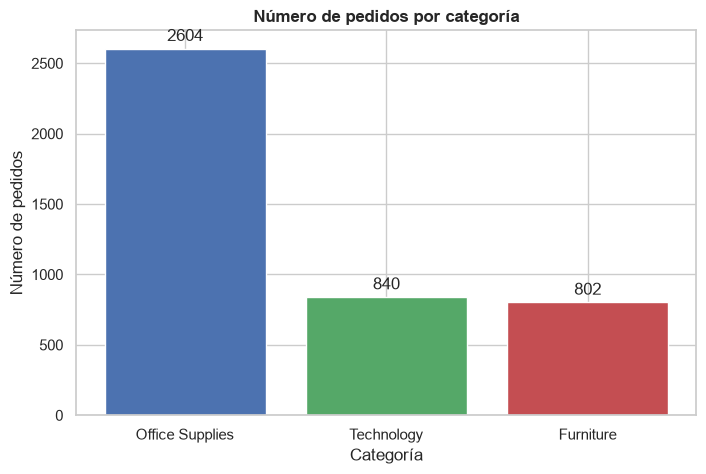

In [7]:
conteo_categoria = df["Category"].value_counts()

fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.bar(conteo_categoria.index, conteo_categoria.values, color=["#4C72B0", "#55A868", "#C44E52"])
ax.bar_label(barras, padding=3)
ax.set_title("Número de pedidos por categoría")
ax.set_xlabel("Categoría")
ax.set_ylabel("Número de pedidos")
plt.show()

# Conclusión: Office Supplies concentra la mayoría de los pedidos (2.604, cerca del 61%),
# casi tres veces más que Technology o Furniture. Es la categoría de compra más frecuente,
# aunque son productos de precio bajo.

### 3.2 Matplotlib: distribución de las ventas (histograma)

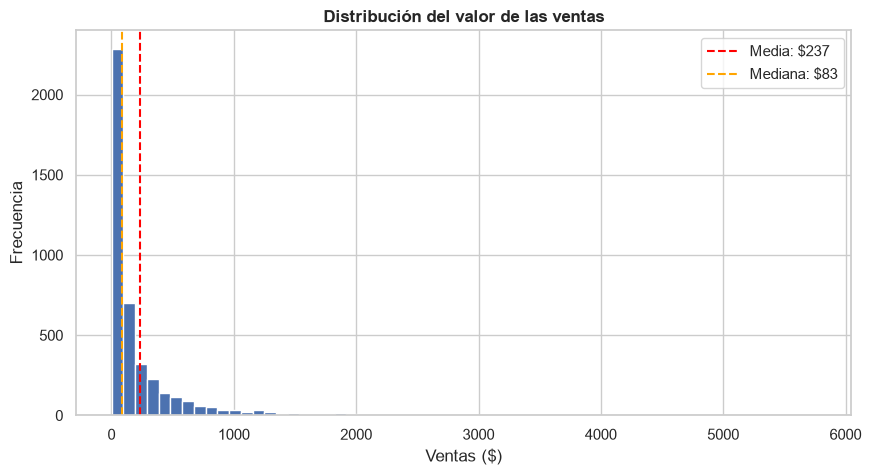

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(df["Sales"], bins=60, color="#4C72B0", edgecolor="white")
ax.axvline(df["Sales"].mean(), color="red", linestyle="--", label=f"Media: ${df['Sales'].mean():.0f}")
ax.axvline(df["Sales"].median(), color="orange", linestyle="--", label=f"Mediana: ${df['Sales'].median():.0f}")
ax.set_title("Distribución del valor de las ventas")
ax.set_xlabel("Ventas ($)")
ax.set_ylabel("Frecuencia")
ax.legend()
plt.show()

# Conclusión: la distribución está muy sesgada a la derecha. La mayoría de las ventas son
# pequeñas (mediana de $83), pero unas pocas ventas grandes (hasta $5.760) suben la media a $237.
# Por eso la mediana representa mejor una venta "típica".

### 3.3 Seaborn: beneficio por categoría (boxplot)

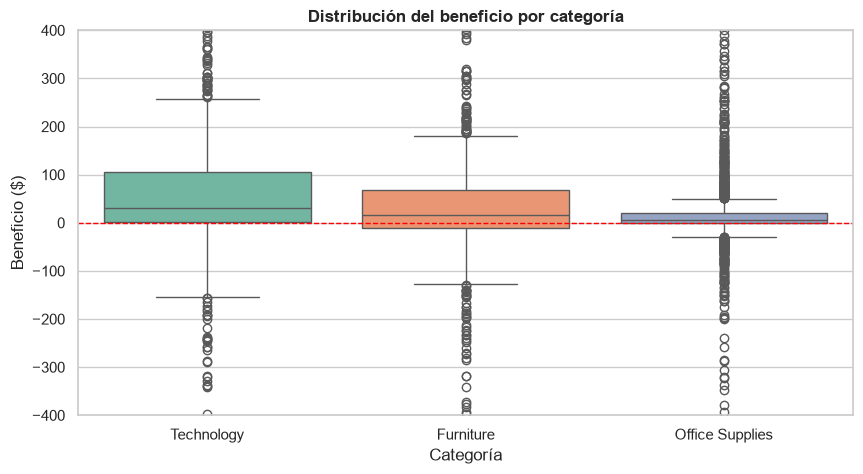

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df, x="Category", y="Profit", hue="Category", palette="Set2", legend=False, ax=ax)
ax.axhline(0, color="red", linestyle="--", linewidth=1)
ax.set_ylim(-400, 400)  # se recorta el eje para ver mejor las cajas
ax.set_title("Distribución del beneficio por categoría")
ax.set_xlabel("Categoría")
ax.set_ylabel("Beneficio ($)")
plt.show()

# Conclusión: Technology tiene la mediana de beneficio más alta ($30) y la caja más amplia:
# deja más beneficio por venta, pero también más variable. Office Supplies tiene una caja estrecha
# cerca de cero (mediana de $6), son ventas de poco margen. En Furniture el primer cuartil es negativo,
# lo que indica que al menos una de cada cuatro ventas de muebles tiene pérdida.

### 3.4 Seaborn: ventas por segmento de cliente (violinplot)

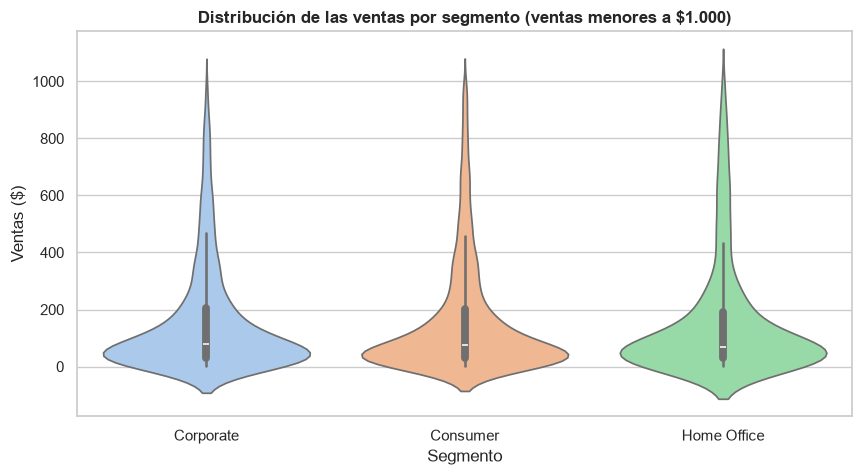

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.violinplot(data=df[df["Sales"] < 1000], x="Segment", y="Sales", hue="Segment",
               palette="pastel", legend=False, ax=ax)
ax.set_title("Distribución de las ventas por segmento (ventas menores a $1.000)")
ax.set_xlabel("Segmento")
ax.set_ylabel("Ventas ($)")
plt.show()

# Conclusión: los tres segmentos tienen una forma muy parecida, con la mayor concentración
# por debajo de $200. El tipo de cliente no cambia mucho el valor de cada venta;
# la diferencia entre segmentos está en la cantidad de pedidos (Consumer tiene más).

## 4. Gráficos bivariantes

### 4.1 Matplotlib: evolución mensual de ventas y beneficios (líneas)

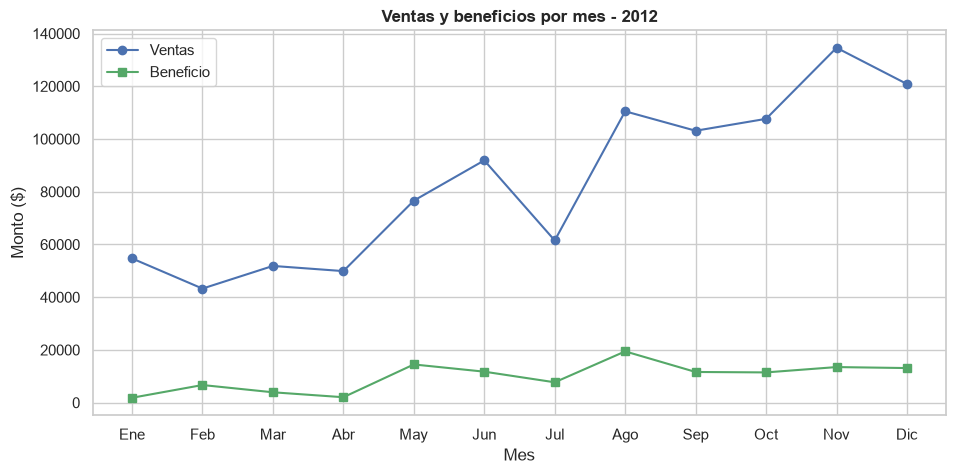

In [11]:
ventas_mes = df.groupby("Mes")[["Sales", "Profit"]].sum()
meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(meses, ventas_mes["Sales"], marker="o", color="#4C72B0", label="Ventas")
ax.plot(meses, ventas_mes["Profit"], marker="s", color="#55A868", label="Beneficio")
ax.set_title("Ventas y beneficios por mes - 2012")
ax.set_xlabel("Mes")
ax.set_ylabel("Monto ($)")
ax.legend()
plt.show()

# Conclusión: las ventas crecen durante el año. El primer semestre está por debajo de $92.000
# al mes y el segundo pasa de $100.000 en casi todos los meses, con el pico en noviembre ($134.600).
# El beneficio no crece al mismo ritmo: su mejor mes es agosto ($19.400) y en noviembre o diciembre
# no aumenta tanto como las ventas.

### 4.2 Seaborn: ventas por mercado y categoría (barras agrupadas)

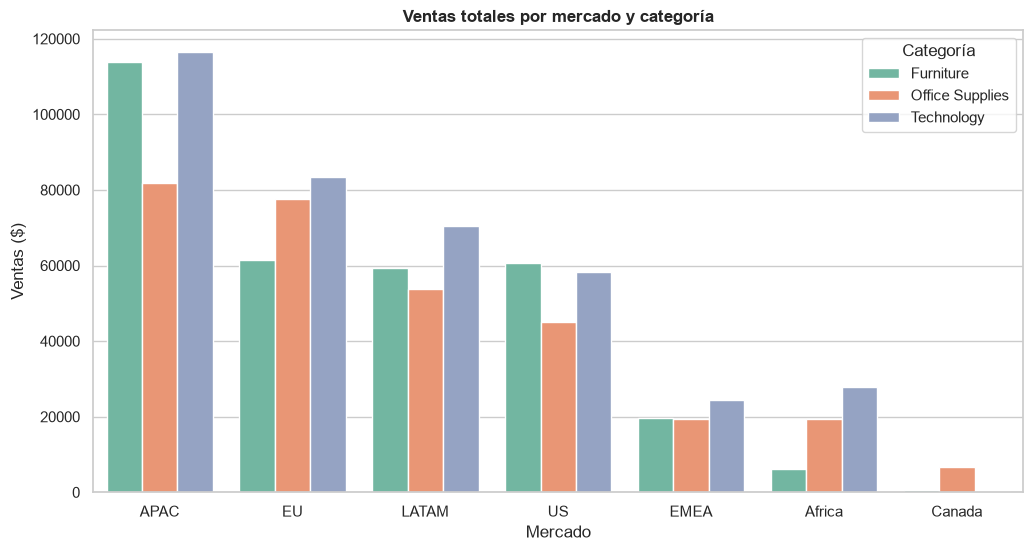

In [12]:
ventas_mercado = df.groupby(["Market", "Category"], as_index=False)["Sales"].sum()
orden_mercados = df.groupby("Market")["Sales"].sum().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=ventas_mercado, x="Market", y="Sales", hue="Category",
            order=orden_mercados, palette="Set2", ax=ax)
ax.set_title("Ventas totales por mercado y categoría")
ax.set_xlabel("Mercado")
ax.set_ylabel("Ventas ($)")
ax.legend(title="Categoría")
plt.show()

# Conclusión: APAC es el mercado más grande, seguido de EU y LATAM. Technology es la categoría
# que más vende en la mayoría de los mercados, aunque Office Supplies tenga más pedidos.
# Las excepciones son US, donde lidera Furniture, y Canada, donde casi todo es Office Supplies.
# Canada, Africa y EMEA tienen un volumen mucho menor.

### 4.3 Seaborn: descuento vs beneficio (regplot)

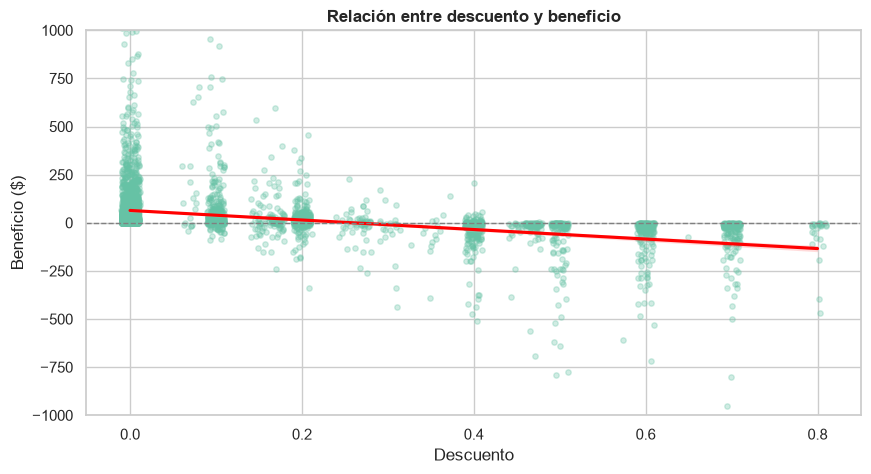

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.regplot(data=df, x="Discount", y="Profit", scatter_kws={"alpha": 0.3, "s": 15},
            line_kws={"color": "red"}, x_jitter=0.01, ax=ax)
ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.set_ylim(-1000, 1000)
ax.set_title("Relación entre descuento y beneficio")
ax.set_xlabel("Descuento")
ax.set_ylabel("Beneficio ($)")
plt.show()

# Conclusión: la recta de regresión baja. A mayor descuento, menor beneficio.
# Desde un 20-30% de descuento la mayoría de las ventas quedan en pérdida.

## 5. Gráficos multivariantes

### 5.1 Matplotlib: ventas vs beneficio coloreado por descuento

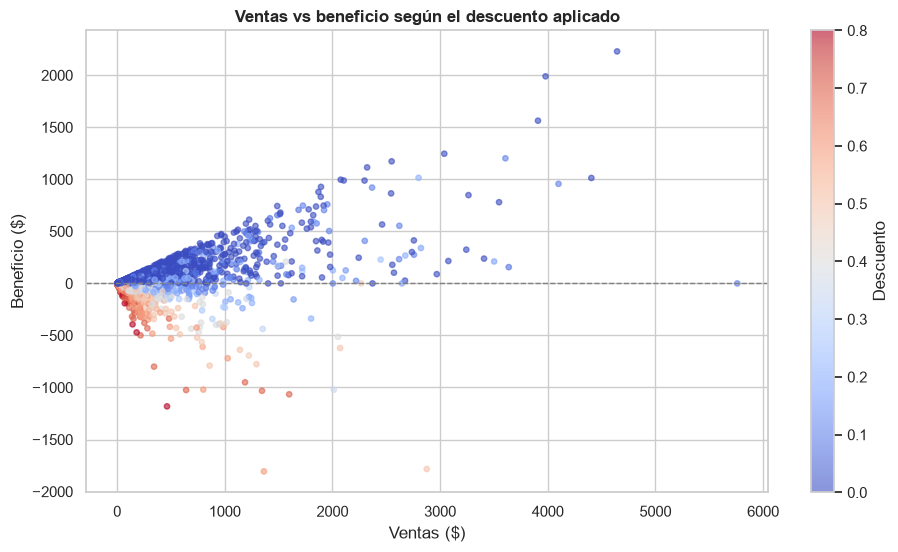

In [14]:
fig, ax = plt.subplots(figsize=(11, 6))
puntos = ax.scatter(df["Sales"], df["Profit"], c=df["Discount"], cmap="coolwarm", alpha=0.6, s=15)
fig.colorbar(puntos, ax=ax, label="Descuento")
ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.set_title("Ventas vs beneficio según el descuento aplicado")
ax.set_xlabel("Ventas ($)")
ax.set_ylabel("Beneficio ($)")
plt.show()

# Conclusión: los puntos azules (sin descuento o con descuento bajo) suben junto con las ventas,
# es decir, vender más deja más beneficio. Los puntos rojos (descuento alto) quedan por debajo de cero
# incluso en ventas grandes. El descuento explica buena parte de las pérdidas.

### 5.2 Seaborn: heatmap de correlación

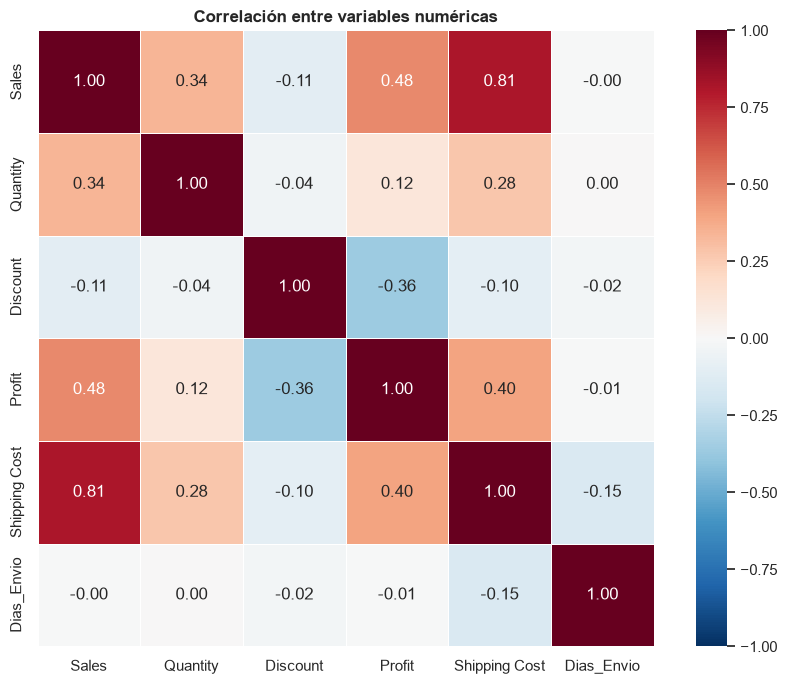

In [15]:
variables = ["Sales", "Quantity", "Discount", "Profit", "Shipping Cost", "Dias_Envio"]
correlacion = df[variables].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(correlacion, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            square=True, linewidths=0.5, ax=ax)
ax.set_title("Correlación entre variables numéricas")
plt.tight_layout()
plt.savefig("heatmap_correlacion.png", dpi=150)
plt.show()

# Conclusión:
# - Sales y Shipping Cost tienen la correlación más alta (0.81): pedidos más grandes cuestan más de enviar.
# - Sales y Profit tienen correlación positiva moderada (0.48).
# - Discount es la única variable con correlación negativa con Profit (-0.36), lo que confirma el gráfico anterior.
# - Los días de envío casi no se relacionan con las demás variables.

### 5.3 Seaborn: pairplot por categoría

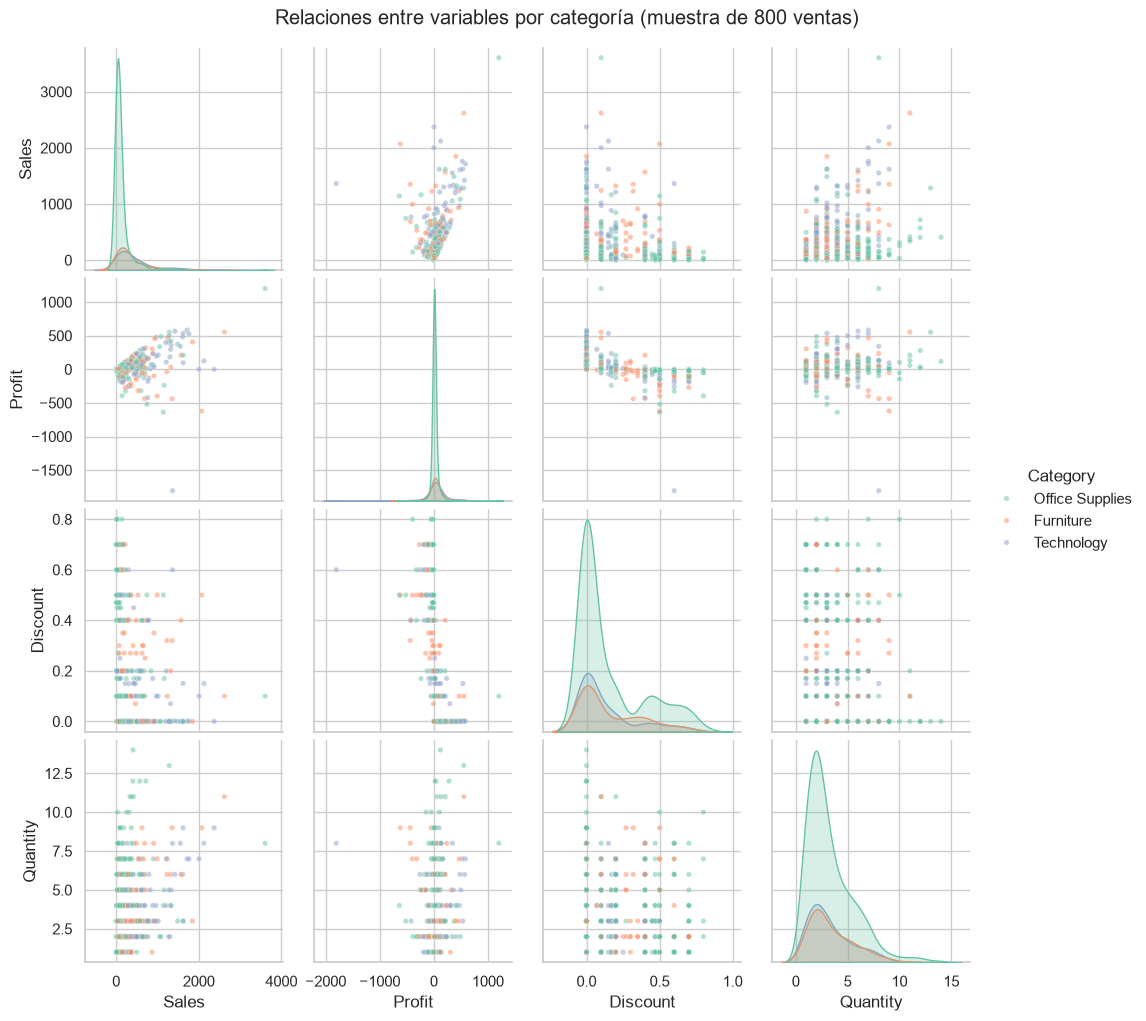

In [16]:
# Se usa una muestra para que el gráfico cargue rápido
muestra = df.sample(800, random_state=42)

grafico = sns.pairplot(muestra, vars=["Sales", "Profit", "Discount", "Quantity"],
                       hue="Category", palette="Set2", plot_kws={"alpha": 0.5, "s": 15})
grafico.figure.suptitle("Relaciones entre variables por categoría (muestra de 800 ventas)", y=1.02)
plt.show()

# Conclusión: Technology y Furniture llegan a ventas y beneficios más altos que Office Supplies.
# En todas las categorías se repite el patrón: con descuentos altos el beneficio es negativo.

## 6. Figura con subplots

Resumen del negocio en una sola figura con 4 gráficos. Se guarda como imagen (`resumen_superstore.png`).

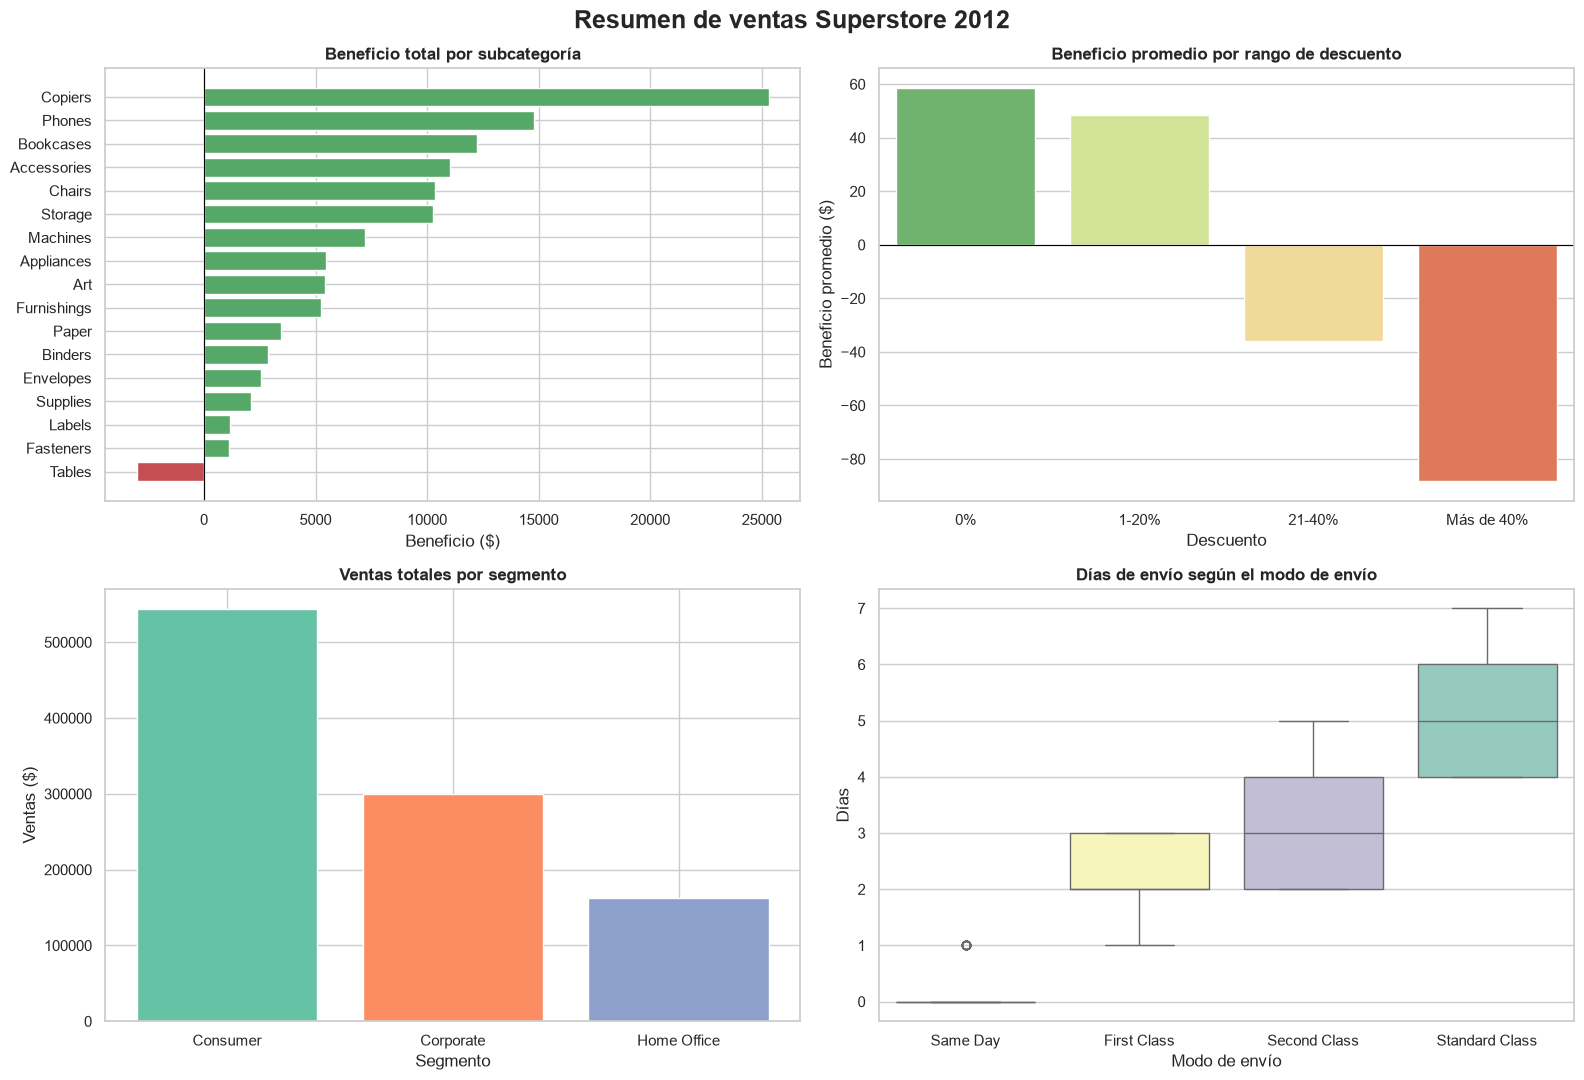

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle("Resumen de ventas Superstore 2012", fontsize=18, fontweight="bold")

# 1. Beneficio por subcategoría
beneficio_sub = df.groupby("Sub-Category")["Profit"].sum().sort_values()
colores = ["#C44E52" if valor < 0 else "#55A868" for valor in beneficio_sub]
axes[0, 0].barh(beneficio_sub.index, beneficio_sub.values, color=colores)
axes[0, 0].axvline(0, color="black", linewidth=0.8)
axes[0, 0].set_title("Beneficio total por subcategoría")
axes[0, 0].set_xlabel("Beneficio ($)")

# 2. Beneficio promedio según rango de descuento
df["Rango_Descuento"] = pd.cut(df["Discount"], bins=[-0.01, 0, 0.2, 0.4, 1],
                               labels=["0%", "1-20%", "21-40%", "Más de 40%"])
sns.barplot(data=df, x="Rango_Descuento", y="Profit", hue="Rango_Descuento",
            palette="RdYlGn_r", errorbar=None, legend=False, dodge=False, ax=axes[0, 1])
axes[0, 1].axhline(0, color="black", linewidth=0.8)
axes[0, 1].set_title("Beneficio promedio por rango de descuento")
axes[0, 1].set_xlabel("Descuento")
axes[0, 1].set_ylabel("Beneficio promedio ($)")

# 3. Ventas por segmento
ventas_segmento = df.groupby("Segment")["Sales"].sum().sort_values(ascending=False)
axes[1, 0].bar(ventas_segmento.index, ventas_segmento.values, color=sns.color_palette("Set2", 3))
axes[1, 0].set_title("Ventas totales por segmento")
axes[1, 0].set_xlabel("Segmento")
axes[1, 0].set_ylabel("Ventas ($)")

# 4. Días de envío por modo de envío
orden_envio = ["Same Day", "First Class", "Second Class", "Standard Class"]
sns.boxplot(data=df, x="Ship Mode", y="Dias_Envio", hue="Ship Mode", order=orden_envio,
            palette="Set3", legend=False, ax=axes[1, 1])
axes[1, 1].set_title("Días de envío según el modo de envío")
axes[1, 1].set_xlabel("Modo de envío")
axes[1, 1].set_ylabel("Días")

plt.tight_layout()
plt.savefig("resumen_superstore.png", dpi=150, bbox_inches="tight")
plt.show()

# Conclusiones:
# 1. Tables es la única subcategoría con pérdidas (-$3.014). Copiers y Phones son las más rentables.
# 2. Sin descuento el beneficio promedio es de $59 por venta; con descuentos de 21-40% cae a -$36
#    y con más de 40% a -$88. Los descuentos altos generan pérdidas.
# 3. Consumer es el segmento que más vende, seguido de Corporate y Home Office.
# 4. Los modos de envío cumplen lo esperado: Same Day sale el mismo día, First Class tarda unos 2 días,
#    Second Class unos 3 y Standard Class unos 5.

## 7. Conclusiones generales

- **Ventas en crecimiento:** las ventas aumentan durante 2012 y el segundo semestre es el más fuerte, con el pico en noviembre. El beneficio no crece en la misma proporción.
- **El descuento es el principal problema:** a partir de un 20% de descuento las ventas tienden a dar pérdida. El 25% de las ventas del año terminaron con beneficio negativo.
- **Productos:** Technology es la categoría más rentable. Office Supplies tiene más pedidos pero de menor valor. Tables es la única subcategoría con pérdidas en el año.
- **Mercados:** APAC, EU y LATAM concentran la mayor parte de las ventas.
- **Envíos:** los tiempos de entrega son coherentes con cada modo de envío.

**Recomendación:** revisar la política de descuentos, sobre todo los mayores al 20%, y analizar los precios y costos de la subcategoría Tables.

Imágenes guardadas: `heatmap_correlacion.png` y `resumen_superstore.png`.